In [1]:
!pip install yfinance ta pytorch-forecasting pytorch-lightning shap -q

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 403.1/403.1 kB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.3/857.3 kB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.6/853.6 kB 50.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.8/160.8 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 24.7 MB/s eta 0:00:00


In [2]:
!pip install pytorch-forecasting==1.7.0 lightning==2.6.1 -q

In [3]:
import pytorch_forecasting
import lightning
print("pytorch_forecasting:", pytorch_forecasting.__version__)
print("lightning:", lightning.__version__)

pytorch_forecasting: 1.7.0
lightning: 2.6.1


In [4]:
import yfinance as yf

df_tsla  = yf.download("TSLA",  start="2019-01-01", end="2024-12-31")
df_sp500 = yf.download("^GSPC", start="2019-01-01", end="2024-12-31")

print("TSLA shape :", df_tsla.shape)
print("SP500 shape:", df_sp500.shape)

# fix multi-level columns
df_tsla.columns  = df_tsla.columns.get_level_values(0)
df_sp500.columns = df_sp500.columns.get_level_values(0)

# keep only what we need
df_tsla  = df_tsla[["Open", "High", "Low", "Close", "Volume"]]
df_sp500 = df_sp500[["Open", "High", "Low", "Close", "Volume"]]

print(df_tsla.columns.tolist())
print(df_sp500.columns.tolist())

print("TSLA rows :", len(df_tsla))
print("SP500 rows:", len(df_sp500))

/tmp/ipykernel_3909/337356020.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_tsla  = yf.download("TSLA",  start="2019-01-01", end="2024-12-31")
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_3909/337356020.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_sp500 = yf.download("^GSPC", start="2019-01-01", end="2024-12-31")
[*********************100%***********************]  1 of 1 completed

TSLA shape : (1509, 5)
SP500 shape: (1509, 5)
['Open', 'High', 'Low', 'Close', 'Volume']
['Open', 'High', 'Low', 'Close', 'Volume']
TSLA rows : 1509
SP500 rows: 1509


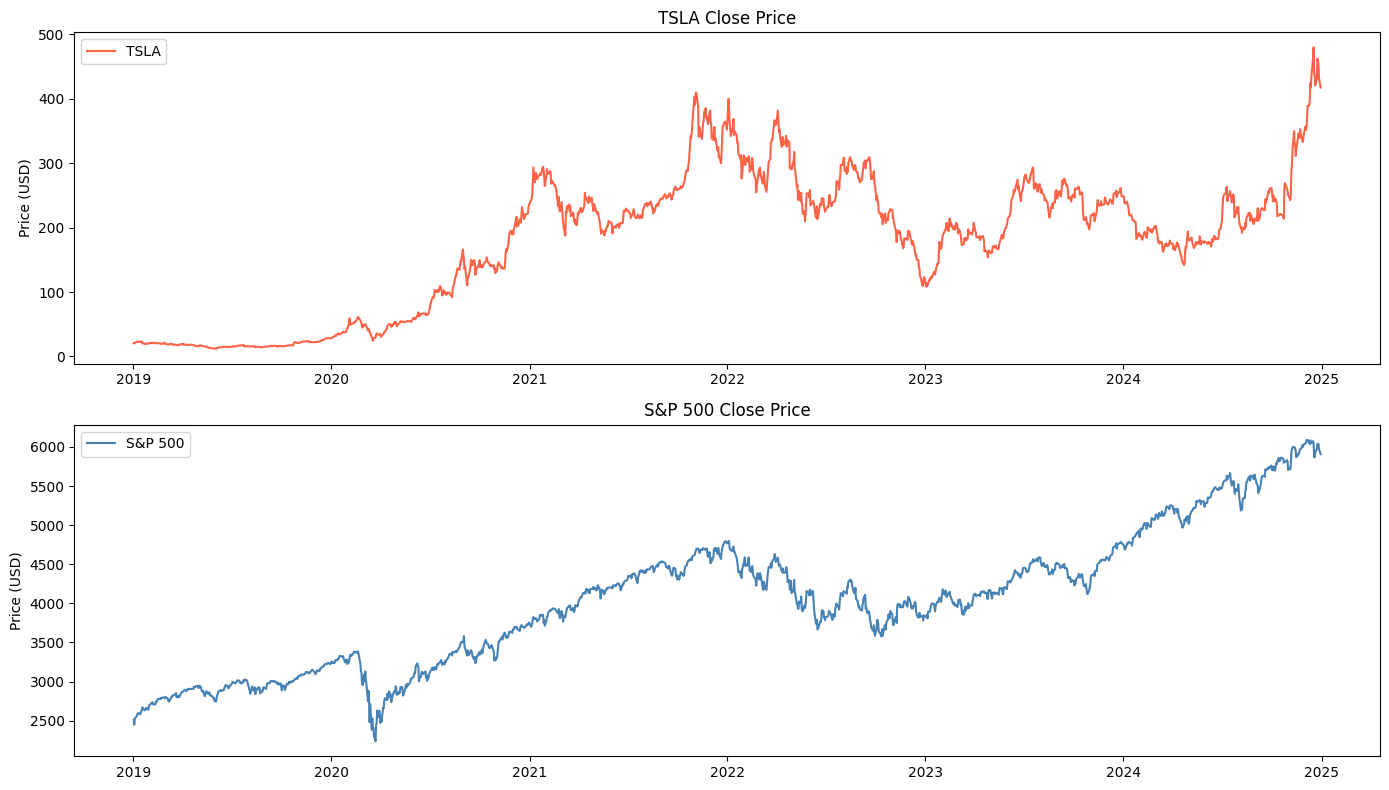

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(df_tsla["Close"],  color="tomato",     label="TSLA")
axes[0].set_title("TSLA Close Price")
axes[0].set_ylabel("Price (USD)")
axes[0].legend()

axes[1].plot(df_sp500["Close"], color="steelblue",  label="S&P 500")
axes[1].set_title("S&P 500 Close Price")
axes[1].set_ylabel("Price (USD)")
axes[1].legend()

plt.tight_layout()
plt.show()

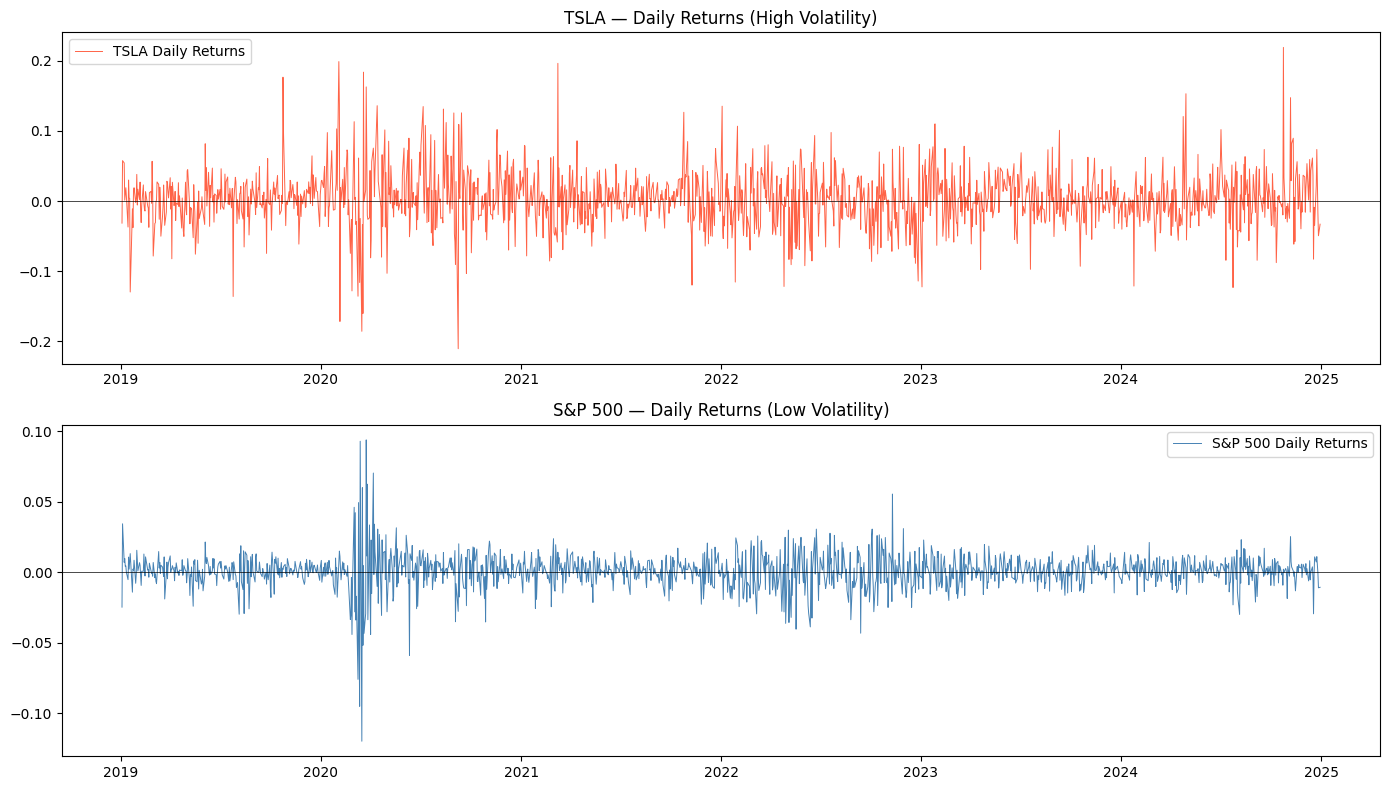

In [6]:
# proves TSLA is harder to predict

df_tsla["Returns"]  = df_tsla["Close"].pct_change()
df_sp500["Returns"] = df_sp500["Close"].pct_change()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(df_tsla["Returns"],  color="tomato",    linewidth=0.7, label="TSLA Daily Returns")
axes[0].axhline(0, color="black", linewidth=0.5)
axes[0].set_title("TSLA — Daily Returns (High Volatility)")
axes[0].legend()

axes[1].plot(df_sp500["Returns"], color="steelblue", linewidth=0.7, label="S&P 500 Daily Returns")
axes[1].axhline(0, color="black", linewidth=0.5)
axes[1].set_title("S&P 500 — Daily Returns (Low Volatility)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [7]:
# Rolling 30-day volatility (std of returns)
tsla_vol  = df_tsla["Returns"].std()
sp500_vol = df_sp500["Returns"].std()

print(f"TSLA  daily volatility : {tsla_vol:.4f}  ({tsla_vol*100:.2f}%)")
print(f"SP500 daily volatility : {sp500_vol:.4f}  ({sp500_vol*100:.2f}%)")
print(f"\nTSLA is {tsla_vol/sp500_vol:.1f}x more volatile than S&P 500")

TSLA  daily volatility : 0.0406  (4.06%)
SP500 daily volatility : 0.0127  (1.27%)

TSLA is 3.2x more volatile than S&P 500


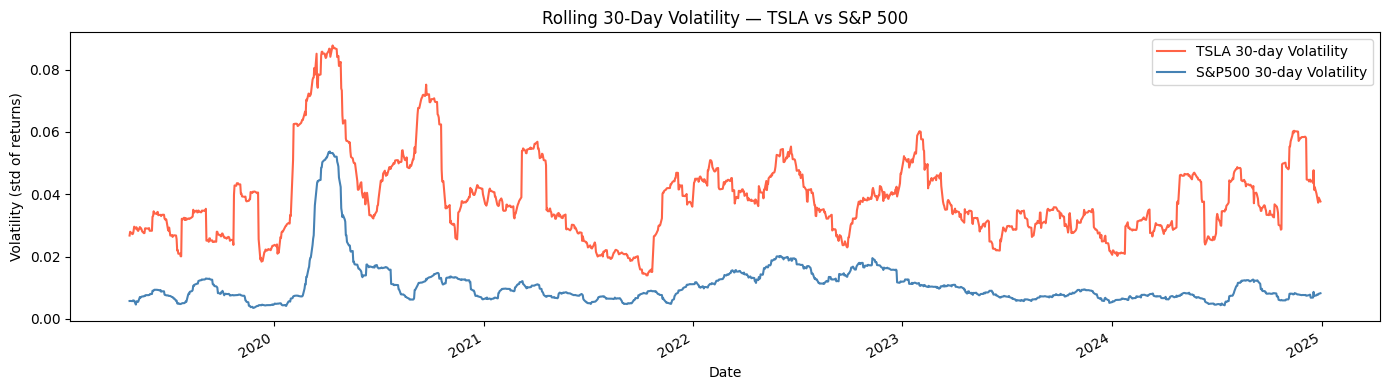

In [9]:
#  EDA section

fig, ax = plt.subplots(figsize=(14, 4))

df_tsla["Returns"].rolling(30).std().plot(ax=ax, color="tomato",    label="TSLA 30-day Volatility")
df_sp500["Returns"].rolling(30).std().plot(ax=ax, color="steelblue", label="S&P500 30-day Volatility")

ax.set_title("Rolling 30-Day Volatility — TSLA vs S&P 500")
ax.set_ylabel("Volatility (std of returns)")
ax.legend()
plt.tight_layout()
plt.show()



In [10]:
import ta
import numpy as np

# Writing ONE function and applying to both datasets
# This ensures INPUT_SIZE stays the same for both models

def add_features(df):
    close  = df["Close"]  # add .squeeze() here
    high   = df["High"]   # add .squeeze() here
    low    = df["Low"]     # add .squeeze() here
    volume = df["Volume"]  # add .squeeze() here

    # rest of the function stays exactly the same

    # trend
    df["SMA_10"]    = ta.trend.SMAIndicator(close, 10).sma_indicator()
    df["SMA_50"]    = ta.trend.SMAIndicator(close, 50).sma_indicator()
    df["EMA_12"]    = ta.trend.EMAIndicator(close, 12).ema_indicator()
    df["EMA_26"]    = ta.trend.EMAIndicator(close, 26).ema_indicator()
    df["MACD"]      = ta.trend.MACD(close).macd()
    df["MACD_sig"]  = ta.trend.MACD(close).macd_signal()
    df["MACD_diff"] = ta.trend.MACD(close).macd_diff()

    # momentum
    df["RSI"]       = ta.momentum.RSIIndicator(close, 14).rsi()
    df["Stoch_K"]   = ta.momentum.StochasticOscillator(high, low, close).stoch()
    df["ROC"]       = ta.momentum.ROCIndicator(close, 12).roc()

    # volatility
    bb = ta.volatility.BollingerBands(close)
    df["BB_upper"]  = bb.bollinger_hband()
    df["BB_lower"]  = bb.bollinger_lband()
    df["BB_width"]  = bb.bollinger_wband()
    df["ATR"]       = ta.volatility.AverageTrueRange(high, low, close).average_true_range()

    # volume
    df["OBV"]       = ta.volume.OnBalanceVolumeIndicator(close, volume).on_balance_volume()

    # lag features
    for lag in [1, 2, 3, 5, 10]:
        df[f"Close_lag_{lag}"] = close.shift(lag)

    # returns
    df["Log_Return"] = np.log(close / close.shift(1))

    df.dropna(inplace=True)
    return df

df_tsla  = add_features(df_tsla)
df_sp500 = add_features(df_sp500)

print("TSLA  features:", df_tsla.shape[1])
print("SP500 features:", df_sp500.shape[1])


TSLA  features: 27
SP500 features: 27


In [11]:
FEATURE_COLS = [c for c in df_tsla.columns if c not in ["Open", "High", "Low", "Volume"]]

print("Features:", FEATURE_COLS)
print("Total   :", len(FEATURE_COLS))
# same for both datasets

Features: ['Close', 'Returns', 'SMA_10', 'SMA_50', 'EMA_12', 'EMA_26', 'MACD', 'MACD_sig', 'MACD_diff', 'RSI', 'Stoch_K', 'ROC', 'BB_upper', 'BB_lower', 'BB_width', 'ATR', 'OBV', 'Close_lag_1', 'Close_lag_2', 'Close_lag_3', 'Close_lag_5', 'Close_lag_10', 'Log_Return']
Total   : 23


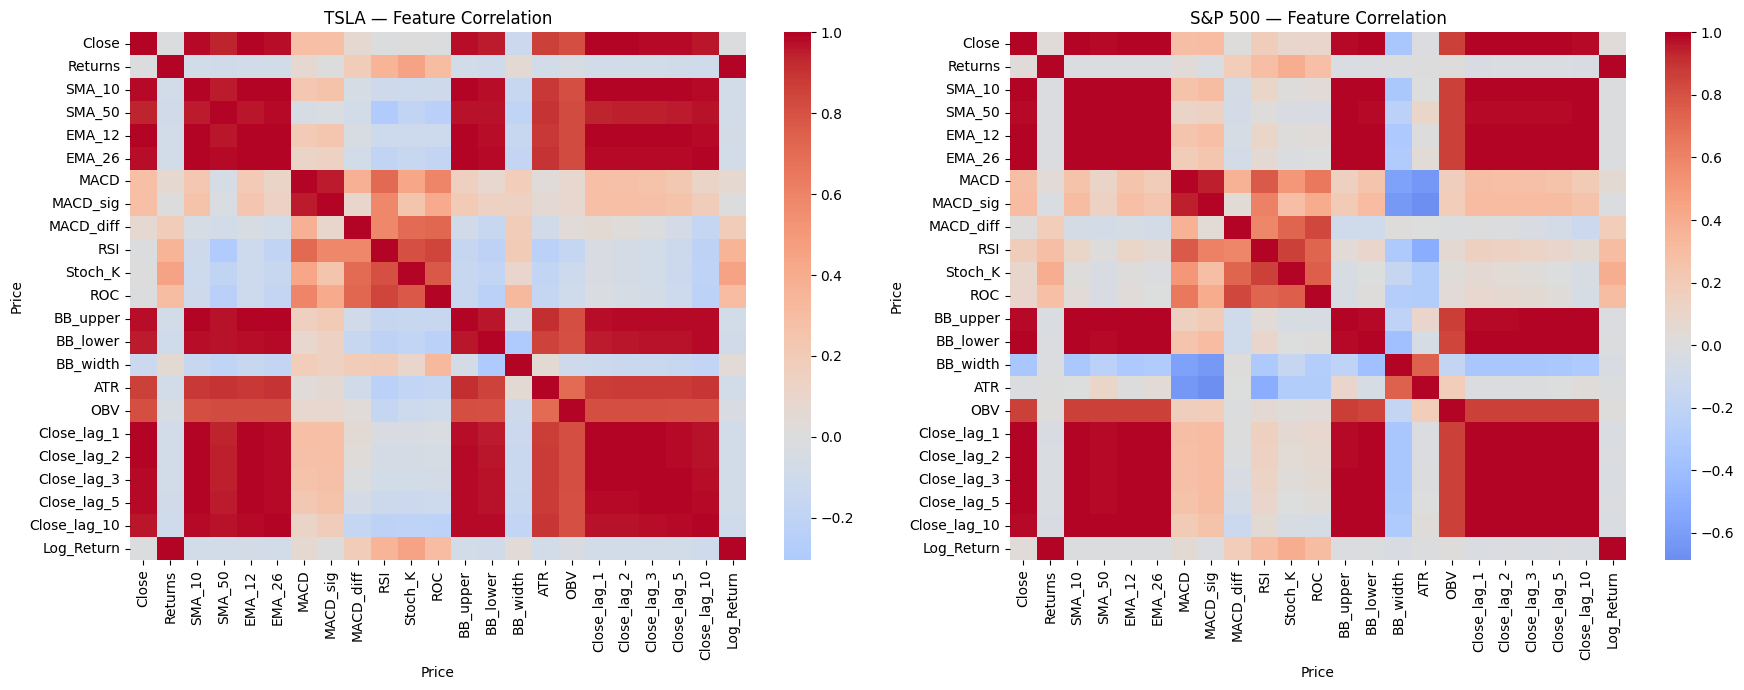

In [12]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(df_tsla[FEATURE_COLS].corr(),  cmap="coolwarm", center=0,
            annot=False, ax=axes[0])
axes[0].set_title("TSLA — Feature Correlation")

sns.heatmap(df_sp500[FEATURE_COLS].corr(), cmap="coolwarm", center=0,
            annot=False, ax=axes[1])
axes[1].set_title("S&P 500 — Feature Correlation")

plt.tight_layout()
plt.show()

In [13]:
df_tsla["Target"]  = np.log(df_tsla["Close"] / df_tsla["Close"].shift(1))
df_sp500["Target"] = np.log(df_sp500["Close"] / df_sp500["Close"].shift(1))

df_tsla.dropna(inplace=True)
df_sp500.dropna(inplace=True)

print("TSLA  rows:", len(df_tsla))
print("SP500 rows:", len(df_sp500))

TSLA  rows: 1410
SP500 rows: 1410


In [14]:
FEATURE_COLS = [c for c in df_tsla.columns
                if c not in ["Open","High","Low","Volume","Target"]]

print("features:", FEATURE_COLS)
print("total   :", len(FEATURE_COLS))

features: ['Close', 'Returns', 'SMA_10', 'SMA_50', 'EMA_12', 'EMA_26', 'MACD', 'MACD_sig', 'MACD_diff', 'RSI', 'Stoch_K', 'ROC', 'BB_upper', 'BB_lower', 'BB_width', 'ATR', 'OBV', 'Close_lag_1', 'Close_lag_2', 'Close_lag_3', 'Close_lag_5', 'Close_lag_10', 'Log_Return']
total   : 23


In [15]:
from sklearn.preprocessing import StandardScaler

def preprocess(df, feature_cols):
    X = df[feature_cols].values
    y = df[["Target"]].values

    n         = len(df)
    train_end = int(n * 0.70)
    val_end   = int(n * 0.85)

    X_train = X[:train_end]
    X_val   = X[train_end:val_end]
    X_test  = X[val_end:]

    y_train = y[:train_end]
    y_val   = y[train_end:val_end]
    y_test  = y[val_end:]

    # scale X only
    scaler_X = StandardScaler()
    X_train_s = scaler_X.fit_transform(X_train)
    X_val_s   = scaler_X.transform(X_val)
    X_test_s  = scaler_X.transform(X_test)

    # NO scaling on y — raw log returns are already small enough
    print(f"y_train: {y_train.min():.4f} to {y_train.max():.4f}")
    print(f"y_val  : {y_val.min():.4f} to {y_val.max():.4f}")
    print(f"y_test : {y_test.min():.4f} to {y_test.max():.4f}")

    return (X_train_s, X_val_s, X_test_s,
            y_train, y_val, y_test,
            train_end, val_end)

(X_train_tsla,  X_val_tsla,  X_test_tsla,
 y_train_tsla,  y_val_tsla,  y_test_tsla,
 train_end_tsla, val_end_tsla) = preprocess(df_tsla, FEATURE_COLS)

print()

(X_train_sp500, X_val_sp500, X_test_sp500,
 y_train_sp500, y_val_sp500, y_test_sp500,
 train_end_sp500, val_end_sp500) = preprocess(df_sp500, FEATURE_COLS)

y_train: -0.2365 to 0.1814
y_val  : -0.1293 to 0.0962
y_test : -0.1316 to 0.1982

y_train: -0.1277 to 0.0897
y_val  : -0.0165 to 0.0209
y_test : -0.0304 to 0.0250


In [16]:
print("TSLA target raw range:")
print(df_tsla["Target"].min(), "to", df_tsla["Target"].max())

print("\nSP500 target raw range:")
print(df_sp500["Target"].min(), "to", df_sp500["Target"].max())

TSLA target raw range:
-0.23651789445767657 to 0.19818699146920774

SP500 target raw range:
-0.12765219747281742 to 0.08968323251796326


In [17]:
def make_sequences(X, y, seq_len=60, pred_len=5):
    Xs, ys = [], []
    for i in range(len(X) - seq_len - pred_len + 1):
        Xs.append(X[i : i+seq_len])
        ys.append(y[i+seq_len : i+seq_len+pred_len].flatten())
    return np.array(Xs), np.array(ys)

X_tr_tsla,  y_tr_tsla  = make_sequences(X_train_tsla,  y_train_tsla)
X_vl_tsla,  y_vl_tsla  = make_sequences(X_val_tsla,    y_val_tsla)
X_te_tsla,  y_te_tsla  = make_sequences(X_test_tsla,   y_test_tsla)

X_tr_sp500, y_tr_sp500 = make_sequences(X_train_sp500, y_train_sp500)
X_vl_sp500, y_vl_sp500 = make_sequences(X_val_sp500,   y_val_sp500)
X_te_sp500, y_te_sp500 = make_sequences(X_test_sp500,  y_test_sp500)

print("TSLA  sequences:", X_tr_tsla.shape, y_tr_tsla.shape)
print("SP500 sequences:", X_tr_sp500.shape, y_tr_sp500.shape)

TSLA  sequences: (922, 60, 23) (922, 5)
SP500 sequences: (922, 60, 23) (922, 5)


In [18]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("using:", device)

def to_tensors(X_tr, y_tr, X_vl, y_vl, X_te, y_te):
    return (
        torch.tensor(X_tr, dtype=torch.float32).to(device),
        torch.tensor(y_tr, dtype=torch.float32).to(device),
        torch.tensor(X_vl, dtype=torch.float32).to(device),
        torch.tensor(y_vl, dtype=torch.float32).to(device),
        torch.tensor(X_te, dtype=torch.float32).to(device),
        torch.tensor(y_te, dtype=torch.float32).to(device),
    )

(X_tr_tsla_t,  y_tr_tsla_t,  X_vl_tsla_t,
 y_vl_tsla_t,  X_te_tsla_t,  y_te_tsla_t)  = to_tensors(
    X_tr_tsla, y_tr_tsla, X_vl_tsla,
    y_vl_tsla, X_te_tsla, y_te_tsla)

(X_tr_sp500_t, y_tr_sp500_t, X_vl_sp500_t,
 y_vl_sp500_t, X_te_sp500_t, y_te_sp500_t) = to_tensors(
    X_tr_sp500, y_tr_sp500, X_vl_sp500,
    y_vl_sp500, X_te_sp500, y_te_sp500)

print("tensors ready")

using: cuda
tensors ready


In [19]:
from torch.utils.data import DataLoader, TensorDataset

def make_loaders(X_tr_t, y_tr_t, X_vl_t, y_vl_t):
    train = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=64, shuffle=False)
    val   = DataLoader(TensorDataset(X_vl_t, y_vl_t), batch_size=64)
    return train, val

train_loader_tsla,  val_loader_tsla  = make_loaders(
    X_tr_tsla_t, y_tr_tsla_t, X_vl_tsla_t, y_vl_tsla_t)

train_loader_sp500, val_loader_sp500 = make_loaders(
    X_tr_sp500_t, y_tr_sp500_t, X_vl_sp500_t, y_vl_sp500_t)

print("loaders ready")

loaders ready


In [20]:
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

INPUT_SIZE = X_tr_tsla.shape[2]

class LSTMAttention(nn.Module):
    def __init__(self, input_size, hidden_size=128, num_layers=2,
                 dropout=0.3, pred_len=5):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True, dropout=dropout)
        self.attn  = nn.Linear(hidden_size, 1)
        self.fc    = nn.Linear(hidden_size, pred_len)
        self.drop  = nn.Dropout(dropout)

    def forward(self, x):
        out, _ = self.lstm(x)               # (B, seq, hidden)
        attn_w = torch.softmax(self.attn(out), dim=1)   # (B, seq, 1)
        context = (attn_w * out).sum(dim=1)              # (B, hidden)
        return self.fc(self.drop(context)), attn_w

print("INPUT_SIZE:", INPUT_SIZE)

INPUT_SIZE: 23


In [21]:
def train_model(model, train_loader, X_vl_t, y_vl_t, save_name, epochs=300):
    optimizer  = torch.optim.Adam(model.parameters(), lr=0.005)
    criterion  = nn.MSELoss()
    scheduler  = torch.optim.lr_scheduler.ReduceLROnPlateau(
                     optimizer, patience=15, factor=0.5, min_lr=1e-7)

    train_losses, val_losses = [], []
    best_val   = float("inf")
    patience   = 0
    EARLY_STOP = 50

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            pred, _ = model(xb)
            loss    = criterion(pred, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            epoch_loss += loss.item()

        avg_train = epoch_loss / len(train_loader)

        model.eval()
        with torch.no_grad():
            val_pred, _ = model(X_vl_t)
            val_loss    = criterion(val_pred, y_vl_t).item()

        scheduler.step(val_loss)
        train_losses.append(avg_train)
        val_losses.append(val_loss)

        if val_loss < best_val:
            best_val = val_loss
            patience = 0
            torch.save(model.state_dict(), save_name)
        else:
            patience += 1

        if epoch % 10 == 0:
            print(f"epoch {epoch:3d} | train: {avg_train:.6f} | val: {val_loss:.6f}")

        if patience >= EARLY_STOP:
            print(f"early stopping at epoch {epoch}")
            break

    model.load_state_dict(torch.load(save_name))
    print(f"done. best val loss: {best_val:.6f}")
    return model, train_losses, val_losses

In [22]:
print("training TSLA...")
model_tsla = LSTMAttention(input_size=INPUT_SIZE).to(device)
model_tsla, tsla_train_losses, tsla_val_losses = train_model(
    model_tsla, train_loader_tsla,
    X_vl_tsla_t, y_vl_tsla_t,
    save_name="best_lstm_tsla.pt"
)

training TSLA...
epoch   0 | train: 0.004116 | val: 0.001394
epoch  10 | train: 0.001915 | val: 0.000908
epoch  20 | train: 0.001885 | val: 0.000908
epoch  30 | train: 0.001890 | val: 0.000944
epoch  40 | train: 0.001851 | val: 0.000890
epoch  50 | train: 0.001863 | val: 0.000892
epoch  60 | train: 0.001827 | val: 0.000937
epoch  70 | train: 0.001836 | val: 0.000892
early stopping at epoch 72
done. best val loss: 0.000881


In [23]:
print("training SP500...")
model_sp500 = LSTMAttention(input_size=INPUT_SIZE).to(device)
model_sp500, sp500_train_losses, sp500_val_losses = train_model(
    model_sp500, train_loader_sp500,
    X_vl_sp500_t, y_vl_sp500_t,
    save_name="best_lstm_sp500.pt"
)

training SP500...
epoch   0 | train: 0.002686 | val: 0.001105
epoch  10 | train: 0.000265 | val: 0.000101
epoch  20 | train: 0.000220 | val: 0.000062
epoch  30 | train: 0.000217 | val: 0.000073
epoch  40 | train: 0.000217 | val: 0.000077
epoch  50 | train: 0.000215 | val: 0.000081
epoch  60 | train: 0.000216 | val: 0.000082
early stopping at epoch 66
done. best val loss: 0.000059


In [24]:
def get_lstm_preds(model, X_te_t, y_te, df, val_end, seq_len=60):
    model.eval()
    with torch.no_grad():
        pred_returns, attn_w = model(X_te_t)

    pred_returns = pred_returns.cpu().numpy()
    attn_w       = attn_w.cpu().numpy()
    actual_returns = y_te  # already raw log returns

    close_prices = df["Close"].values
    base_prices  = close_prices[val_end + seq_len : val_end + seq_len + len(pred_returns)]

    pred_prices   = np.zeros_like(pred_returns)
    actual_prices = np.zeros_like(actual_returns)

    for i in range(len(pred_returns)):
        base = base_prices[i]
        for d in range(5):
            pred_prices[i, d]   = base * np.exp(np.sum(pred_returns[i, :d+1]))
            actual_prices[i, d] = base * np.exp(np.sum(actual_returns[i, :d+1]))

    return pred_prices, actual_prices, attn_w



lstm_preds_tsla,  y_actual_tsla,  attn_tsla  = get_lstm_preds(
    model_tsla,  X_te_tsla_t,  y_te_tsla,
    df_tsla,  val_end_tsla)

lstm_preds_sp500, y_actual_sp500, attn_sp500 = get_lstm_preds(
    model_sp500, X_te_sp500_t, y_te_sp500,
    df_sp500, val_end_sp500)

print("TSLA  preds:", lstm_preds_tsla.shape)
print("SP500 preds:", lstm_preds_sp500.shape)



TSLA  preds: (148, 5)
SP500 preds: (148, 5)


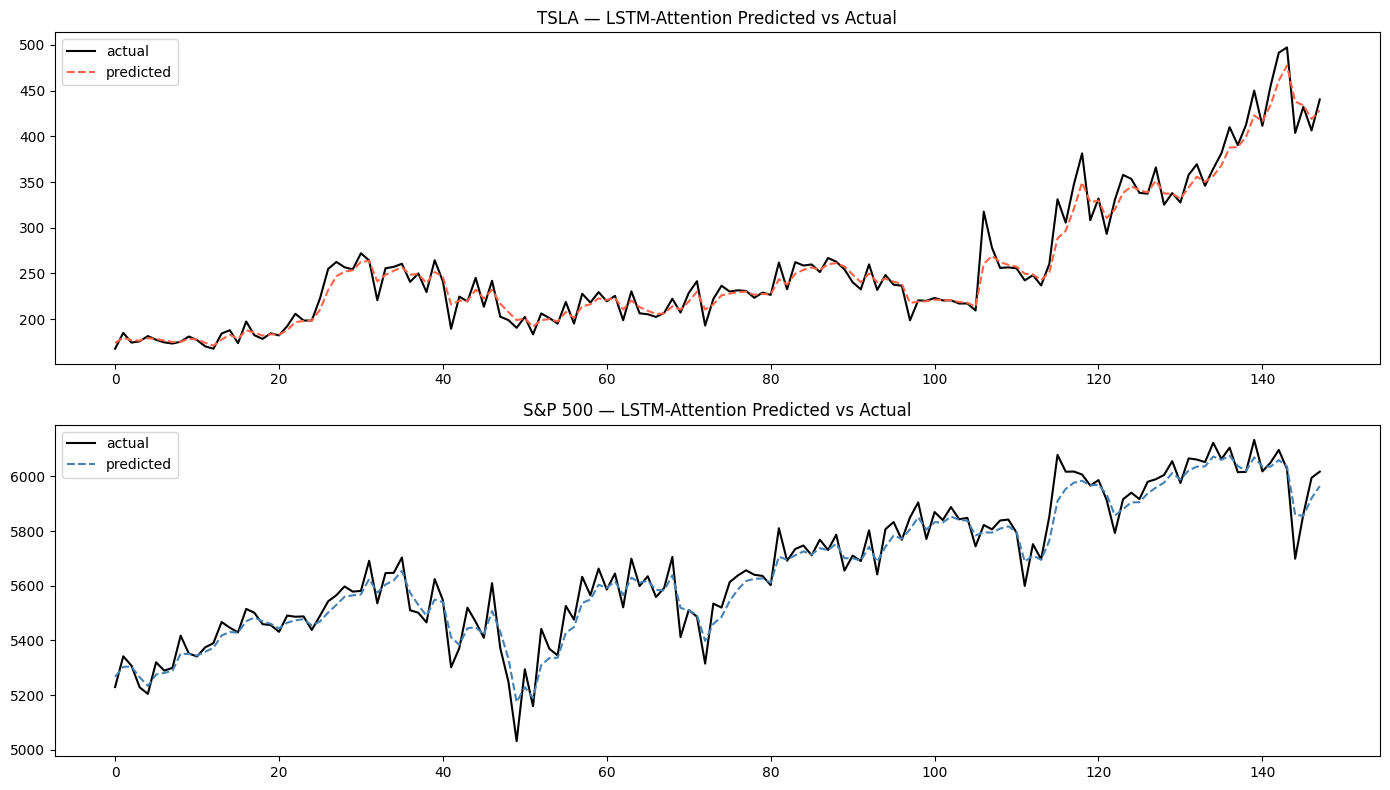

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(y_actual_tsla[:, 0],   label="actual",    color="black")
axes[0].plot(lstm_preds_tsla[:, 0], label="predicted", color="tomato",    linestyle="--")
axes[0].set_title("TSLA — LSTM-Attention Predicted vs Actual")
axes[0].legend()

axes[1].plot(y_actual_sp500[:, 0],   label="actual",    color="black")
axes[1].plot(lstm_preds_sp500[:, 0], label="predicted", color="steelblue", linestyle="--")
axes[1].set_title("S&P 500 — LSTM-Attention Predicted vs Actual")
axes[1].legend()

plt.tight_layout()
plt.show()

In [26]:
print("y_tr_tsla sample:", y_tr_tsla[:3])
print("y_vl_tsla sample:", y_vl_tsla[:3])
print()
print("y_tr min/max:", y_tr_tsla.min(), y_tr_tsla.max())
print("y_vl min/max:", y_vl_tsla.min(), y_vl_tsla.max())

y_tr_tsla sample: [[-0.00428551 -0.02252213  0.00595967 -0.04960079  0.01688594]
 [-0.02252213  0.00595967 -0.04960079  0.01688594 -0.00428821]
 [ 0.00595967 -0.04960079  0.01688594 -0.00428821  0.0070287 ]]
y_vl_tsla sample: [[-0.0110152   0.03417589 -0.01414853 -0.00351186 -0.03322999]
 [ 0.03417589 -0.01414853 -0.00351186 -0.03322999  0.04110507]
 [-0.01414853 -0.00351186 -0.03322999  0.04110507  0.00370874]]

y_tr min/max: -0.23651789445767657 0.18144500086765858
y_vl min/max: -0.12925817170128795 0.09615118904304938


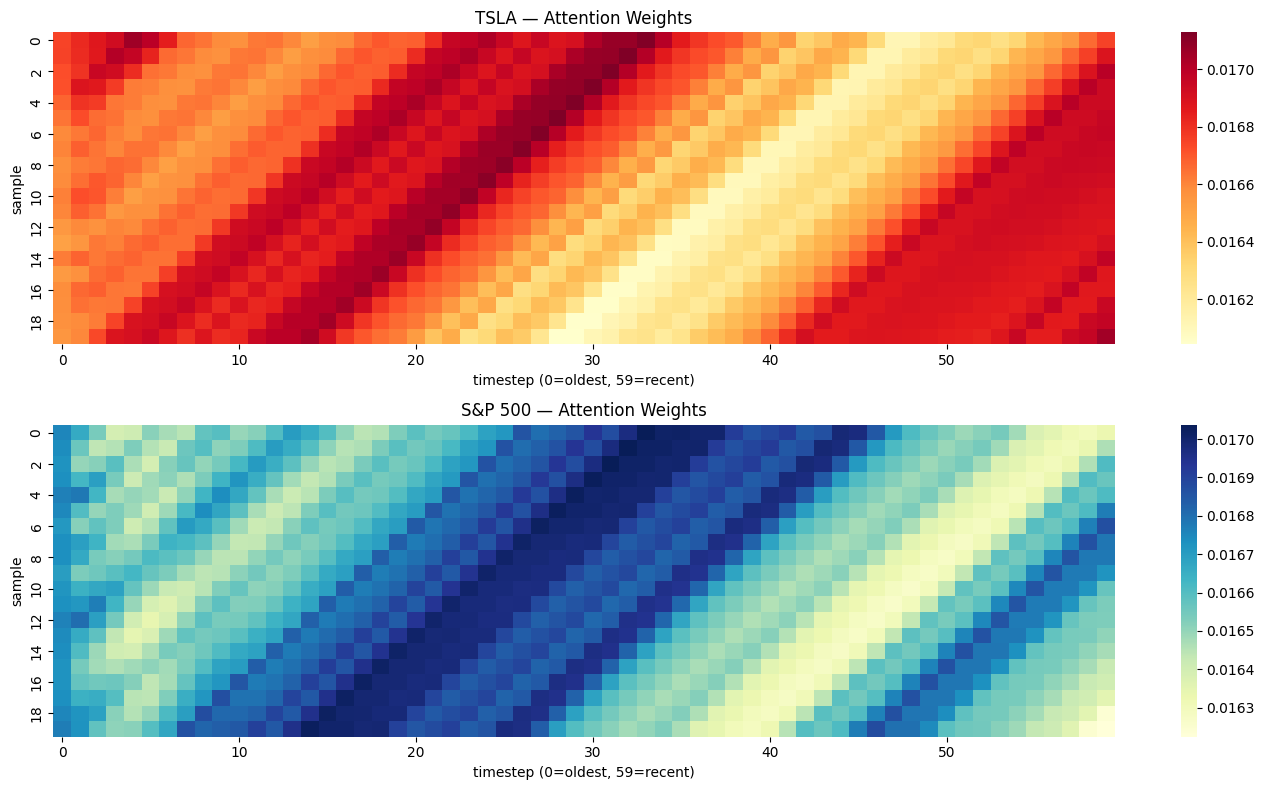

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

sns.heatmap(attn_tsla[:20].squeeze(-1), cmap="YlOrRd", ax=axes[0], xticklabels=10)
axes[0].set_title("TSLA — Attention Weights")
axes[0].set_xlabel("timestep (0=oldest, 59=recent)")
axes[0].set_ylabel("sample")

sns.heatmap(attn_sp500[:20].squeeze(-1), cmap="YlGnBu", ax=axes[1], xticklabels=10)
axes[1].set_title("S&P 500 — Attention Weights")
axes[1].set_xlabel("timestep (0=oldest, 59=recent)")
axes[1].set_ylabel("sample")

plt.tight_layout()
plt.show()

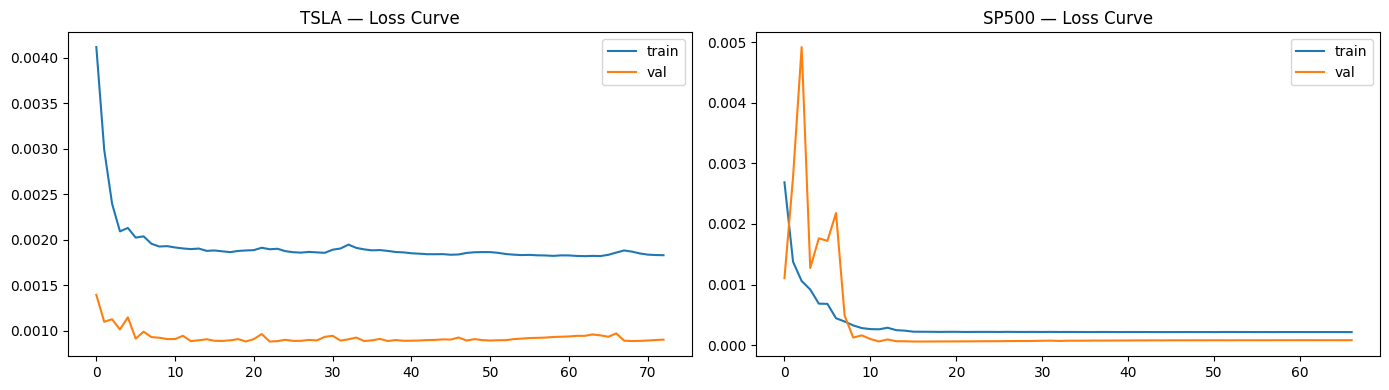

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(tsla_train_losses, label="train")
axes[0].plot(tsla_val_losses,   label="val")
axes[0].set_title("TSLA — Loss Curve")
axes[0].legend()

axes[1].plot(sp500_train_losses, label="train")
axes[1].plot(sp500_val_losses,   label="val")
axes[1].set_title("SP500 — Loss Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def get_metrics(y_true, y_pred, name):
    y_true = y_true.flatten()
    y_pred = y_pred.flatten()
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100
    da   = np.mean(np.sign(np.diff(y_true)) == np.sign(np.diff(y_pred))) * 100
    print(f"{name}")
    print(f"  MAE  : {mae:.4f}")
    print(f"  RMSE : {rmse:.4f}")
    print(f"  MAPE : {mape:.2f}%")
    print(f"  DA%  : {da:.2f}%")
    return {"Model": name, "MAE": mae, "RMSE": rmse, "MAPE%": mape, "DA%": da}

r_lstm_tsla  = get_metrics(y_actual_tsla,  lstm_preds_tsla,  "LSTM-Attention TSLA")
print()
r_lstm_sp500 = get_metrics(y_actual_sp500, lstm_preds_sp500, "LSTM-Attention SP500")

import pandas as pd
lstm_results = pd.DataFrame([r_lstm_tsla, r_lstm_sp500]).set_index("Model").round(4)
print()
print(lstm_results)
lstm_results.to_csv("lstm_results.csv")
print("saved!")

LSTM-Attention TSLA
  MAE  : 15.0775
  RMSE : 22.8675
  MAPE : 5.34%
  DA%  : 48.58%

LSTM-Attention SP500
  MAE  : 74.5092
  RMSE : 99.3421
  MAPE : 1.31%
  DA%  : 42.63%

                          MAE     RMSE   MAPE%      DA%
Model                                                  
LSTM-Attention TSLA   15.0775  22.8675  5.3355  48.5792
LSTM-Attention SP500  74.5092  99.3421  1.3107  42.6252
saved!


In [30]:
from pytorch_forecasting import TemporalFusionTransformer, TimeSeriesDataSet
from pytorch_forecasting.metrics import QuantileLoss
import pytorch_lightning as pl
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint

In [31]:
def prepare_tft(df, stock_name):
    df_tft = df.copy().reset_index()
    df_tft["time_idx"] = range(len(df_tft))
    df_tft["stock_id"] = stock_name

    tft_feats = ["Close", "RSI", "MACD", "EMA_12", "EMA_26",
                 "BB_width", "ATR", "Returns", "Close_lag_1", "Close_lag_2"]
    tft_feats = [c for c in tft_feats if c in df_tft.columns]

    n         = len(df_tft)
    train_end = int(n * 0.70)
    val_end   = int(n * 0.85)

    train_ds = TimeSeriesDataSet(
        df_tft.iloc[:train_end + 5],
        time_idx                   = "time_idx",
        target                     = "Close",
        group_ids                  = ["stock_id"],
        max_encoder_length         = 60,
        max_prediction_length      = 5,
        time_varying_unknown_reals = tft_feats,
        add_relative_time_idx      = True,
        add_target_scales          = True,
        add_encoder_length         = True,
    )

    val_ds = TimeSeriesDataSet.from_dataset(
        train_ds, df_tft.iloc[:val_end + 5],
        predict=True, stop_randomization=True
    )

    test_ds = TimeSeriesDataSet.from_dataset(
        train_ds,
        df_tft.iloc[val_end - 60:],
        predict=False,
        stop_randomization=True
    )

    print(f"{stock_name}: train={train_end}, val={val_end}, test_ds size={len(test_ds)}")
    return train_ds, val_ds, test_ds, train_end, val_end, df_tft

tft_train_tsla,  tft_val_tsla,  tft_test_tsla,  _, _, df_tft_tsla  = prepare_tft(df_tsla,  "TSLA")
tft_train_sp500, tft_val_sp500, tft_test_sp500, _, _, df_tft_sp500 = prepare_tft(df_sp500, "SP500")
print("TFT datasets ready")

TSLA: train=986, val=1198, test_ds size=208
SP500: train=986, val=1198, test_ds size=208
TFT datasets ready


In [32]:
def prepare_tft(df, stock_name):
    df_tft = df.copy().reset_index()
    df_tft["time_idx"] = range(len(df_tft))
    df_tft["stock_id"] = stock_name

    tft_feats = ["Close", "RSI", "MACD", "EMA_12", "EMA_26",
                 "BB_width", "ATR", "Returns", "Close_lag_1", "Close_lag_2"]
    tft_feats = [c for c in tft_feats if c in df_tft.columns]

    n         = len(df_tft)
    train_end = int(n * 0.70)
    val_end   = int(n * 0.85)

    train_ds = TimeSeriesDataSet(
        df_tft.iloc[:train_end + 5],
        time_idx                   = "time_idx",
        target                     = "Close",
        group_ids                  = ["stock_id"],
        max_encoder_length         = 60,
        max_prediction_length      = 5,
        time_varying_unknown_reals = tft_feats,
        add_relative_time_idx      = True,
        add_target_scales          = True,
        add_encoder_length         = True,
    )

    val_ds = TimeSeriesDataSet.from_dataset(
        train_ds, df_tft.iloc[:val_end + 5],
        predict=True, stop_randomization=True
    )

    test_ds = TimeSeriesDataSet.from_dataset(
        train_ds,
        df_tft.iloc[val_end - 60:],
        predict=False,
        stop_randomization=True
    )

    print(f"{stock_name}: train={train_end}, val={val_end}, test_ds size={len(test_ds)}")
    return train_ds, val_ds, test_ds, train_end, val_end, df_tft

tft_train_tsla,  tft_val_tsla,  tft_test_tsla,  _, _, df_tft_tsla  = prepare_tft(df_tsla,  "TSLA")
tft_train_sp500, tft_val_sp500, tft_test_sp500, _, _, df_tft_sp500 = prepare_tft(df_sp500, "SP500")
print("TFT datasets ready")

TSLA: train=986, val=1198, test_ds size=208
SP500: train=986, val=1198, test_ds size=208
TFT datasets ready


In [33]:
import warnings
import lightning as pl
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint

warnings.filterwarnings("ignore", message="X does not have valid feature names",
                        category=UserWarning, module="sklearn")
warnings.filterwarnings("ignore",
                        message="Attribute .* is an instance of `nn.Module`",
                        category=UserWarning, module="lightning")

def train_tft(train_ds, val_ds, save_name, max_epochs=50, patience=10):
    train_dl = train_ds.to_dataloader(train=True,  batch_size=64, num_workers=0)
    val_dl   = val_ds.to_dataloader(  train=False, batch_size=64, num_workers=0)

    tft = TemporalFusionTransformer.from_dataset(
        train_ds,
        learning_rate              = 0.01,
        hidden_size                = 64,
        attention_head_size        = 4,
        dropout                    = 0.1,
        hidden_continuous_size     = 32,
        loss                       = QuantileLoss(),
        reduce_on_plateau_patience = 4,
    )

    print(f"TFT parameters: {sum(p.numel() for p in tft.parameters()):,}")

    trainer = pl.Trainer(
        max_epochs        = max_epochs,
        accelerator       = "gpu" if torch.cuda.is_available() else "cpu",
        devices           = 1,
        gradient_clip_val = 0.1,
        callbacks         = [
            EarlyStopping(monitor="val_loss", patience=patience, mode="min"),
            ModelCheckpoint(monitor="val_loss", filename=save_name, save_top_k=1)
        ],
        logger = False,
    )

    trainer.fit(tft, train_dl, val_dl)
    best = TemporalFusionTransformer.load_from_checkpoint(
        trainer.checkpoint_callback.best_model_path)
    return best, val_dl

In [34]:
print("training TFT on TSLA...")
tft_tsla,  tft_val_dl_tsla  = train_tft(tft_train_tsla,  tft_val_tsla,  "best_tft_tsla")

print("\ntraining TFT on SP500...")
tft_sp500, tft_val_dl_sp500 = train_tft(tft_train_sp500, tft_val_sp500, "best_tft_sp500")

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


training TFT on TSLA...
TFT parameters: 313,563


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃    ┃ Name                               ┃ Type                            ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0  │ loss                               │ QuantileLoss                    │      0 │ train │     0 │
│ 1  │ logging_metrics                    │ ModuleList                      │      0 │ train │     0 │
│ 2  │ input_embeddings                   │ MultiEmbedding                  │      0 │ train │     0 │
│ 3  │ prescalers                         │ ModuleDict                      │    896 │ train │     0 │
│ 4  │ static_variable_selection          │ VariableSelectionNetwork        │ 20.5 K │ train │     0 │
│ 5  │ encoder_variable_selection         │ VariableSelectionNetwork        │ 79.0 K │ train │     0 │
│ 6  │ decoder_variable_selection         │ VariableSelectionNetwork        │  6.7 K │ train │     0 │
│ 7  │ static_context_variable_selection  │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 8  │ static_context_initial_hidden_lstm │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 9  │ static_context_initial_cell_lstm   │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 10 │ static_context_enrichment          │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 11 │ lstm_encoder                       │ LSTM                            │ 33.3 K │ train │     0 │
│ 12 │ lstm_decoder                       │ LSTM                            │ 33.3 K │ train │     0 │
│ 13 │ post_lstm_gate_encoder             │ GatedLinearUnit                 │  8.3 K │ train │     0 │
│ 14 │ post_lstm_add_norm_encoder         │ AddNorm                         │    128 │ train │     0 │
│ 15 │ static_enrichment                  │ GatedResidualNetwork            │ 20.9 K │ train │     0 │
│ 16 │ multihead_attn                     │ InterpretableMultiHeadAttention │ 10.4 K │ train │     0 │
│ 17 │ post_attn_gate_norm                │ GateAddNorm                     │  8.4 K │ train │     0 │
│ 18 │ pos_wise_ff                        │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 19 │ pre_output_gate_norm               │ GateAddNorm                     │  8.4 K │ train │     0 │
│ 20 │ output_layer                       │ Linear                          │    455 │ train │     0 │
└────┴────────────────────────────────────┴─────────────────────────────────┴────────┴───────┴───────┘

Trainable params: 313 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 313 K                                                                                                
Total estimated model params size (MB): 1                                                                          
Modules in train mode: 370                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

...

┏━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃    ┃ Name                               ┃ Type                            ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0  │ loss                               │ QuantileLoss                    │      0 │ train │     0 │
│ 1  │ logging_metrics                    │ ModuleList                      │      0 │ train │     0 │
│ 2  │ input_embeddings                   │ MultiEmbedding                  │      0 │ train │     0 │
│ 3  │ prescalers                         │ ModuleDict                      │    896 │ train │     0 │
│ 4  │ static_variable_selection          │ VariableSelectionNetwork        │ 20.5 K │ train │     0 │
│ 5  │ encoder_variable_selection         │ VariableSelectionNetwork        │ 79.0 K │ train │     0 │
│ 6  │ decoder_variable_selection         │ VariableSelectionNetwork        │  6.7 K │ train │     0 │
│ 7  │ static_context_variable_selection  │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 8  │ static_context_initial_hidden_lstm │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 9  │ static_context_initial_cell_lstm   │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 10 │ static_context_enrichment          │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 11 │ lstm_encoder                       │ LSTM                            │ 33.3 K │ train │     0 │
│ 12 │ lstm_decoder                       │ LSTM                            │ 33.3 K │ train │     0 │
│ 13 │ post_lstm_gate_encoder             │ GatedLinearUnit                 │  8.3 K │ train │     0 │
│ 14 │ post_lstm_add_norm_encoder         │ AddNorm                         │    128 │ train │     0 │
│ 15 │ static_enrichment                  │ GatedResidualNetwork            │ 20.9 K │ train │     0 │
│ 16 │ multihead_attn                     │ InterpretableMultiHeadAttention │ 10.4 K │ train │     0 │
│ 17 │ post_attn_gate_norm                │ GateAddNorm                     │  8.4 K │ train │     0 │
│ 18 │ pos_wise_ff                        │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 19 │ pre_output_gate_norm               │ GateAddNorm                     │  8.4 K │ train │     0 │
│ 20 │ output_layer                       │ Linear                          │    455 │ train │     0 │
└────┴────────────────────────────────────┴─────────────────────────────────┴────────┴───────┴───────┘

Trainable params: 313 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 313 K                                                                                                
Total estimated model params size (MB): 1                                                                          
Modules in train mode: 370                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

In [35]:
def get_tft_preds(model, test_ds, df_tft, stock_name):
    test_dl = test_ds.to_dataloader(train=False, batch_size=64,
                                    num_workers=0, shuffle=False)

    preds = model.predict(
        test_dl,
        mode="prediction",
        trainer_kwargs={"logger": False, "accelerator": "gpu", "devices": 1}
    )

    preds_np = preds.cpu().numpy()  # (n_samples, 5) — Close prices

    # pull actuals from test_ds directly
    actuals = []
    for i in range(len(test_ds)):
        _, target = test_ds[i]
        actuals.append(target[0].numpy())  # shape (5,)
    actuals = np.array(actuals)

    print(f"{stock_name} — preds: {preds_np.shape}, actuals: {actuals.shape}")
    return preds_np, actuals

tft_preds_tsla,  tft_actual_tsla  = get_tft_preds(tft_tsla,  tft_test_tsla,  df_tft_tsla,  "TSLA")
tft_preds_sp500, tft_actual_sp500 = get_tft_preds(tft_sp500, tft_test_sp500, df_tft_sp500, "SP500")

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


TSLA — preds: (208, 5), actuals: (208, 5)


/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


SP500 — preds: (208, 5), actuals: (208, 5)


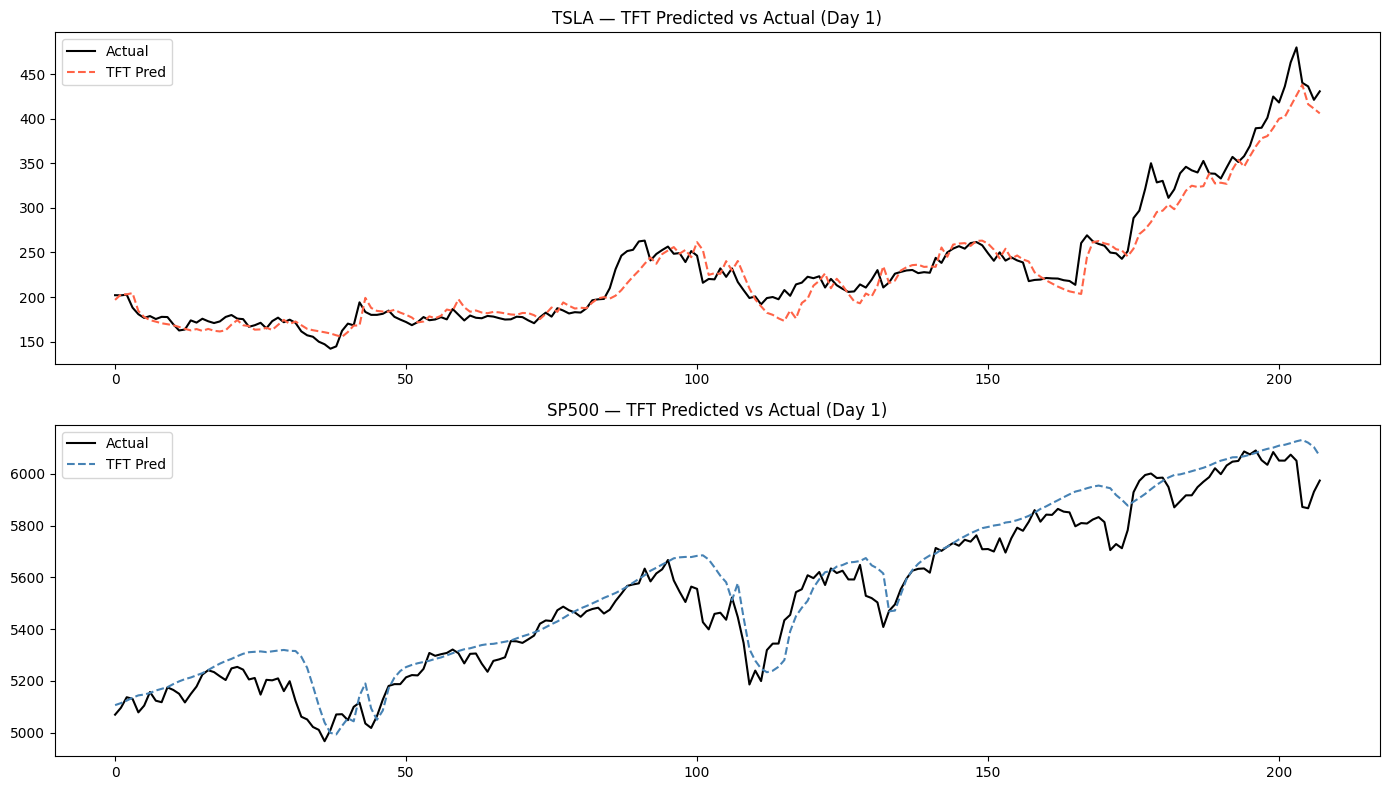

In [36]:
# Pred vs Actual plots
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(tft_actual_tsla[:, 0],  label="Actual",   color="black")
axes[0].plot(tft_preds_tsla[:, 0],   label="TFT Pred", color="tomato",    linestyle="--")
axes[0].set_title("TSLA — TFT Predicted vs Actual (Day 1)")
axes[0].legend()

axes[1].plot(tft_actual_sp500[:, 0], label="Actual",   color="black")
axes[1].plot(tft_preds_sp500[:, 0],  label="TFT Pred", color="steelblue", linestyle="--")
axes[1].set_title("SP500 — TFT Predicted vs Actual (Day 1)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [37]:
# TFT Loss Curves
# extract losses from trainer — need to retrain with logging enabled
# since we used logger=False, we capture them manually

def train_tft_with_losses(train_ds, val_ds, save_name,
                           lr=0.01, dropout=0.1,
                           max_epochs=50, patience=10,
                           plateau_patience=4):
    train_dl = train_ds.to_dataloader(train=True,  batch_size=64, num_workers=0)
    val_dl   = val_ds.to_dataloader(  train=False, batch_size=64, num_workers=0)

    tft = TemporalFusionTransformer.from_dataset(
        train_ds,
        learning_rate              = lr,
        hidden_size                = 64,
        attention_head_size        = 4,
        dropout                    = dropout,
        hidden_continuous_size     = 32,
        loss                       = QuantileLoss(),
        reduce_on_plateau_patience = plateau_patience,
    )

    print(f"TFT parameters: {sum(p.numel() for p in tft.parameters()):,}")

    # use CSV logger to capture losses
    from lightning.pytorch.loggers import CSVLogger
    csv_logger = CSVLogger(".", name=f"tft_logs_{save_name}")

    trainer = pl.Trainer(
        max_epochs        = max_epochs,
        accelerator       = "gpu" if torch.cuda.is_available() else "cpu",
        devices           = 1,
        gradient_clip_val = 0.1,
        callbacks         = [
            EarlyStopping(monitor="val_loss", patience=patience, mode="min"),
            ModelCheckpoint(monitor="val_loss", filename=save_name, save_top_k=1)
        ],
        logger  = csv_logger,   # CSV logger instead of False
        enable_progress_bar = True,
    )

    trainer.fit(tft, train_dl, val_dl)
    best = TemporalFusionTransformer.load_from_checkpoint(
        trainer.checkpoint_callback.best_model_path)

    # read losses from CSV
    import glob
    csv_path = glob.glob(f"tft_logs_{save_name}/version_*/metrics.csv")[0]
    metrics  = pd.read_csv(csv_path)

    train_losses = metrics[metrics["train_loss_epoch"].notna()]["train_loss_epoch"].values
    val_losses   = metrics[metrics["val_loss"].notna()]["val_loss"].values

    # trim to same length
    min_len      = min(len(train_losses), len(val_losses))
    train_losses = train_losses[:min_len]
    val_losses   = val_losses[:min_len]

    print(f"done. epochs run: {min_len}")
    return best, val_dl, train_losses, val_losses


# retrain both with loss tracking
print("training TFT on TSLA...")
tft_tsla, tft_val_dl_tsla, tsla_tft_train_losses, tsla_tft_val_losses = train_tft_with_losses(
    tft_train_tsla, tft_val_tsla, "best_tft_tsla",
    lr=0.01, dropout=0.1, max_epochs=50, patience=10
)

print("\ntraining TFT on SP500...")
tft_sp500, tft_val_dl_sp500, sp500_tft_train_losses, sp500_tft_val_losses = train_tft_with_losses(
    tft_train_sp500, tft_val_sp500, "best_tft_sp500",
    lr=0.005, dropout=0.2, max_epochs=80, patience=20,
    plateau_patience=6
)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


training TFT on TSLA...
TFT parameters: 313,563


┏━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃    ┃ Name                               ┃ Type                            ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0  │ loss                               │ QuantileLoss                    │      0 │ train │     0 │
│ 1  │ logging_metrics                    │ ModuleList                      │      0 │ train │     0 │
│ 2  │ input_embeddings                   │ MultiEmbedding                  │      0 │ train │     0 │
│ 3  │ prescalers                         │ ModuleDict                      │    896 │ train │     0 │
│ 4  │ static_variable_selection          │ VariableSelectionNetwork        │ 20.5 K │ train │     0 │
│ 5  │ encoder_variable_selection         │ VariableSelectionNetwork        │ 79.0 K │ train │     0 │
│ 6  │ decoder_variable_selection         │ VariableSelectionNetwork        │  6.7 K │ train │     0 │
│ 7  │ static_context_variable_selection  │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 8  │ static_context_initial_hidden_lstm │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 9  │ static_context_initial_cell_lstm   │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 10 │ static_context_enrichment          │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 11 │ lstm_encoder                       │ LSTM                            │ 33.3 K │ train │     0 │
│ 12 │ lstm_decoder                       │ LSTM                            │ 33.3 K │ train │     0 │
│ 13 │ post_lstm_gate_encoder             │ GatedLinearUnit                 │  8.3 K │ train │     0 │
│ 14 │ post_lstm_add_norm_encoder         │ AddNorm                         │    128 │ train │     0 │
│ 15 │ static_enrichment                  │ GatedResidualNetwork            │ 20.9 K │ train │     0 │
│ 16 │ multihead_attn                     │ InterpretableMultiHeadAttention │ 10.4 K │ train │     0 │
│ 17 │ post_attn_gate_norm                │ GateAddNorm                     │  8.4 K │ train │     0 │
│ 18 │ pos_wise_ff                        │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 19 │ pre_output_gate_norm               │ GateAddNorm                     │  8.4 K │ train │     0 │
│ 20 │ output_layer                       │ Linear                          │    455 │ train │     0 │
└────┴────────────────────────────────────┴─────────────────────────────────┴────────┴───────┴───────┘

Trainable params: 313 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 313 K                                                                                                
Total estimated model params size (MB): 1                                                                          
Modules in train mode: 370                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

...

Output()

/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.12/dist-packages/lightning/pytorch/loops/fit_loop.py:317: The number of training batches 
(14) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if
you want to see logs for the training epoch.

done. epochs run: 23


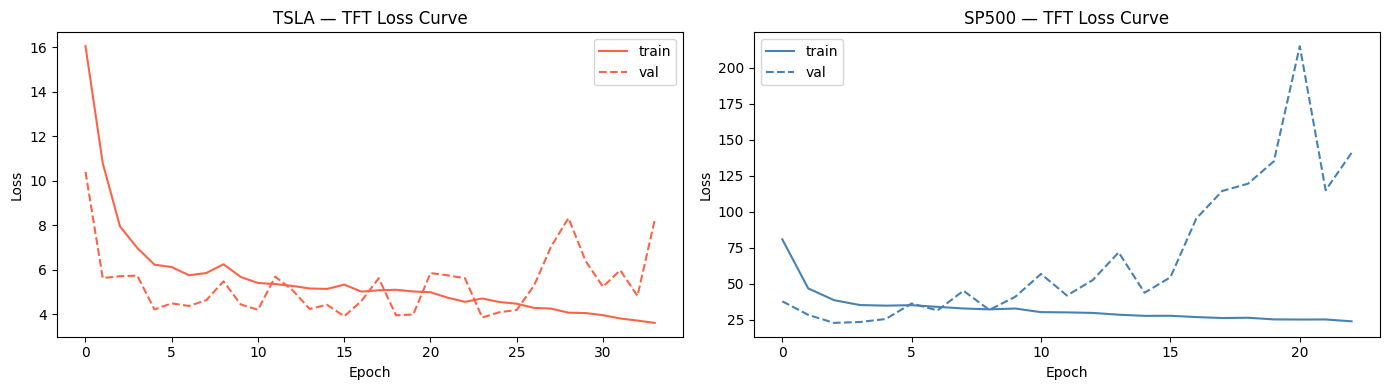

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(tsla_tft_train_losses, label="train", color="tomato")
axes[0].plot(tsla_tft_val_losses,   label="val",   color="tomato", linestyle="--")
axes[0].set_title("TSLA — TFT Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(sp500_tft_train_losses, label="train", color="steelblue")
axes[1].plot(sp500_tft_val_losses,   label="val",   color="steelblue", linestyle="--")
axes[1].set_title("SP500 — TFT Loss Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [39]:
# ONLY retrain SP500 — do NOT touch tft_tsla
tft_train_sp500, tft_val_sp500, tft_test_sp500, _, _, df_tft_sp500 = prepare_tft(df_sp500, "SP500")

print("retraining TFT on SP500 only...")
tft_sp500, tft_val_dl_sp500 = train_tft(
    tft_train_sp500, tft_val_sp500, "best_tft_sp500",
    max_epochs=80, patience=20
)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.12/dist-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /content/checkpoints exists and is not empty.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


SP500: train=986, val=1198, test_ds size=208
retraining TFT on SP500 only...
TFT parameters: 313,563


┏━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃    ┃ Name                               ┃ Type                            ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0  │ loss                               │ QuantileLoss                    │      0 │ train │     0 │
│ 1  │ logging_metrics                    │ ModuleList                      │      0 │ train │     0 │
│ 2  │ input_embeddings                   │ MultiEmbedding                  │      0 │ train │     0 │
│ 3  │ prescalers                         │ ModuleDict                      │    896 │ train │     0 │
│ 4  │ static_variable_selection          │ VariableSelectionNetwork        │ 20.5 K │ train │     0 │
│ 5  │ encoder_variable_selection         │ VariableSelectionNetwork        │ 79.0 K │ train │     0 │
│ 6  │ decoder_variable_selection         │ VariableSelectionNetwork        │  6.7 K │ train │     0 │
│ 7  │ static_context_variable_selection  │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 8  │ static_context_initial_hidden_lstm │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 9  │ static_context_initial_cell_lstm   │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 10 │ static_context_enrichment          │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 11 │ lstm_encoder                       │ LSTM                            │ 33.3 K │ train │     0 │
│ 12 │ lstm_decoder                       │ LSTM                            │ 33.3 K │ train │     0 │
│ 13 │ post_lstm_gate_encoder             │ GatedLinearUnit                 │  8.3 K │ train │     0 │
│ 14 │ post_lstm_add_norm_encoder         │ AddNorm                         │    128 │ train │     0 │
│ 15 │ static_enrichment                  │ GatedResidualNetwork            │ 20.9 K │ train │     0 │
│ 16 │ multihead_attn                     │ InterpretableMultiHeadAttention │ 10.4 K │ train │     0 │
│ 17 │ post_attn_gate_norm                │ GateAddNorm                     │  8.4 K │ train │     0 │
│ 18 │ pos_wise_ff                        │ GatedResidualNetwork            │ 16.8 K │ train │     0 │
│ 19 │ pre_output_gate_norm               │ GateAddNorm                     │  8.4 K │ train │     0 │
│ 20 │ output_layer                       │ Linear                          │    455 │ train │     0 │
└────┴────────────────────────────────────┴─────────────────────────────────┴────────┴───────┴───────┘

Trainable params: 313 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 313 K                                                                                                
Total estimated model params size (MB): 1                                                                          
Modules in train mode: 370                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

In [40]:
def train_tft(train_ds, val_ds, save_name, max_epochs=50, patience=10):
    train_dl = train_ds.to_dataloader(train=True,  batch_size=64, num_workers=0)
    val_dl   = val_ds.to_dataloader(  train=False, batch_size=64, num_workers=0)

    tft = TemporalFusionTransformer.from_dataset(
        train_ds,
        learning_rate              = 0.005,  # lower — SP500 needs more stable training
        hidden_size                = 64,
        attention_head_size        = 4,
        dropout                    = 0.2,    # more regularization
        hidden_continuous_size     = 32,
        loss                       = QuantileLoss(),
        reduce_on_plateau_patience = 6,
    )

    print(f"TFT parameters: {sum(p.numel() for p in tft.parameters()):,}")

    trainer = pl.Trainer(
        max_epochs        = max_epochs,
        accelerator       = "gpu" if torch.cuda.is_available() else "cpu",
        devices           = 1,
        gradient_clip_val = 0.1,
        callbacks         = [
            EarlyStopping(monitor="val_loss", patience=patience, mode="min"),
            ModelCheckpoint(monitor="val_loss", filename=save_name, save_top_k=1)
        ],
        logger = False,
    )

    trainer.fit(tft, train_dl, val_dl)
    best = TemporalFusionTransformer.load_from_checkpoint(
        trainer.checkpoint_callback.best_model_path)
    return best, val_dl

In [41]:
tft_preds_sp500, tft_actual_sp500 = get_tft_preds(tft_sp500, tft_test_sp500, df_tft_sp500, "SP500")

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


SP500 — preds: (208, 5), actuals: (208, 5)


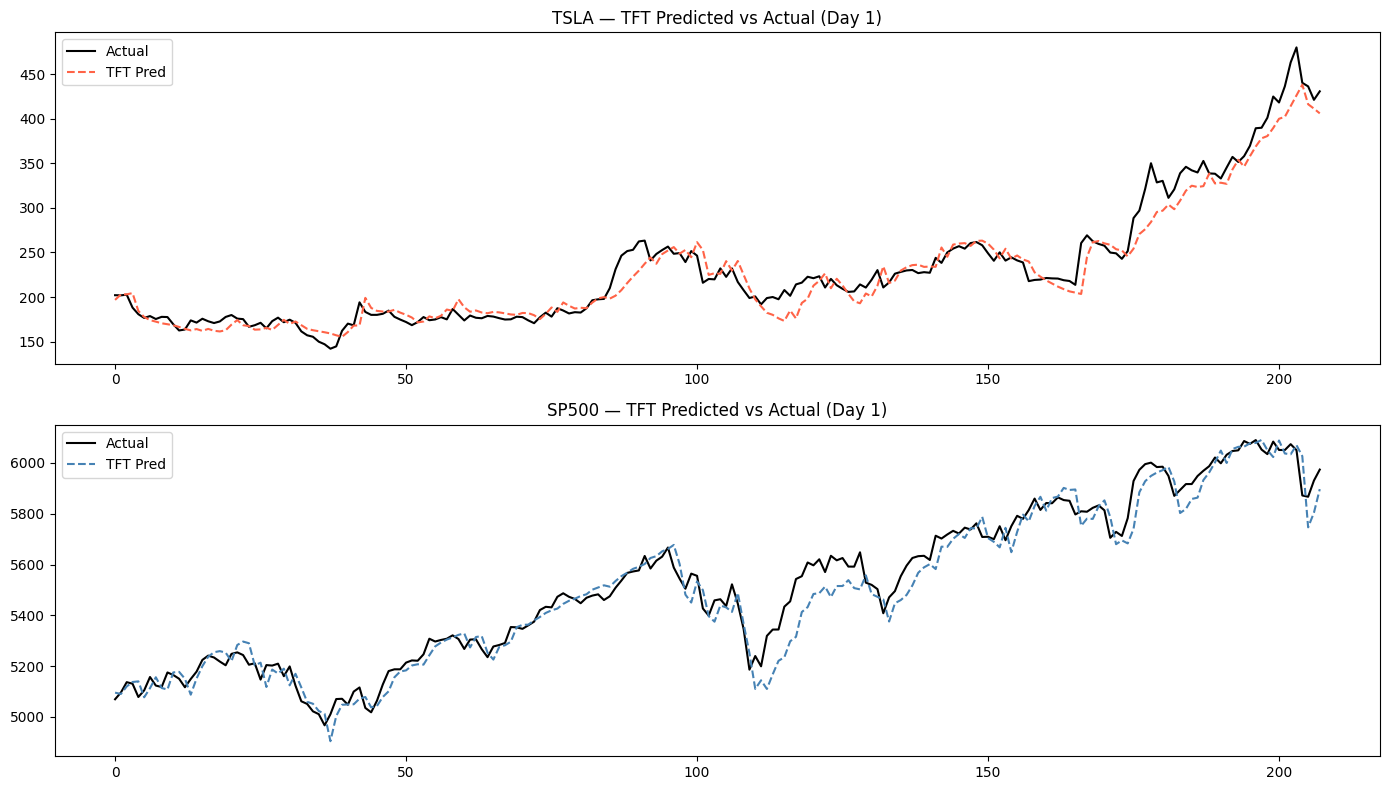

In [42]:
# Pred vs Actual plots
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(tft_actual_tsla[:, 0],  label="Actual",   color="black")
axes[0].plot(tft_preds_tsla[:, 0],   label="TFT Pred", color="tomato",    linestyle="--")
axes[0].set_title("TSLA — TFT Predicted vs Actual (Day 1)")
axes[0].legend()

axes[1].plot(tft_actual_sp500[:, 0], label="Actual",   color="black")
axes[1].plot(tft_preds_sp500[:, 0],  label="TFT Pred", color="steelblue", linestyle="--")
axes[1].set_title("SP500 — TFT Predicted vs Actual (Day 1)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [43]:
r_tft_tsla  = get_metrics(tft_actual_tsla,  tft_preds_tsla,  "TFT TSLA")
print()
r_tft_sp500 = get_metrics(tft_actual_sp500, tft_preds_sp500, "TFT SP500")

TFT TSLA
  MAE  : 16.3098
  RMSE : 22.6861
  MAPE : 6.70%
  DA%  : 52.55%

TFT SP500
  MAE  : 69.3988
  RMSE : 96.1564
  MAPE : 1.25%
  DA%  : 54.38%


In [44]:
# ensemble using percentage blend on normalized predictions
min_tsla  = min(len(lstm_preds_tsla),  len(tft_preds_tsla),  len(tft_actual_tsla))
min_sp500 = min(len(lstm_preds_sp500), len(tft_preds_sp500), len(tft_actual_sp500))

# use tft actuals as ground truth since TFT predicts raw prices
y_true_tsla  = tft_actual_tsla[:min_tsla]
y_true_sp500 = tft_actual_sp500[:min_sp500]

# normalize both predictions to same scale before blending
def normalize_preds(preds, actuals):
    # scale predictions to match actual price range
    pred_mean   = preds.mean()
    actual_mean = actuals.mean()
    scale       = actual_mean / (pred_mean + 1e-8)
    return preds * scale

lstm_tsla_norm  = normalize_preds(lstm_preds_tsla[:min_tsla],  y_true_tsla)
lstm_sp500_norm = normalize_preds(lstm_preds_sp500[:min_sp500], y_true_sp500)

# ensemble
ensemble_tsla  = 0.3 * lstm_tsla_norm  + 0.7 * tft_preds_tsla[:min_tsla]
ensemble_sp500 = 0.3 * lstm_sp500_norm + 0.7 * tft_preds_sp500[:min_sp500]

print("ensemble TSLA  shape:", ensemble_tsla.shape)
print("ensemble SP500 shape:", ensemble_sp500.shape)

ensemble TSLA  shape: (148, 5)
ensemble SP500 shape: (148, 5)


In [45]:
r_ens_tsla  = get_metrics(y_true_tsla,  ensemble_tsla,  "Ensemble TSLA")
print()
r_ens_sp500 = get_metrics(y_true_sp500, ensemble_sp500, "Ensemble SP500")

all_results = pd.DataFrame([
    r_lstm_tsla, r_tft_tsla, r_ens_tsla,
    r_lstm_sp500, r_tft_sp500, r_ens_sp500
]).set_index("Model").round(4)

print(all_results)
all_results.to_csv("final_results.csv")

Ensemble TSLA
  MAE  : 14.0552
  RMSE : 18.0961
  MAPE : 6.86%
  DA%  : 49.26%

Ensemble SP500
  MAE  : 66.9174
  RMSE : 86.1616
  MAPE : 1.25%
  DA%  : 43.98%
                          MAE     RMSE   MAPE%      DA%
Model                                                  
LSTM-Attention TSLA   15.0775  22.8675  5.3355  48.5792
TFT TSLA              16.3098  22.6861  6.6952  52.5505
Ensemble TSLA         14.0552  18.0961  6.8557  49.2558
LSTM-Attention SP500  74.5092  99.3421  1.3107  42.6252
TFT SP500             69.3988  96.1564  1.2540  54.3792
Ensemble SP500        66.9174  86.1616  1.2490  43.9783


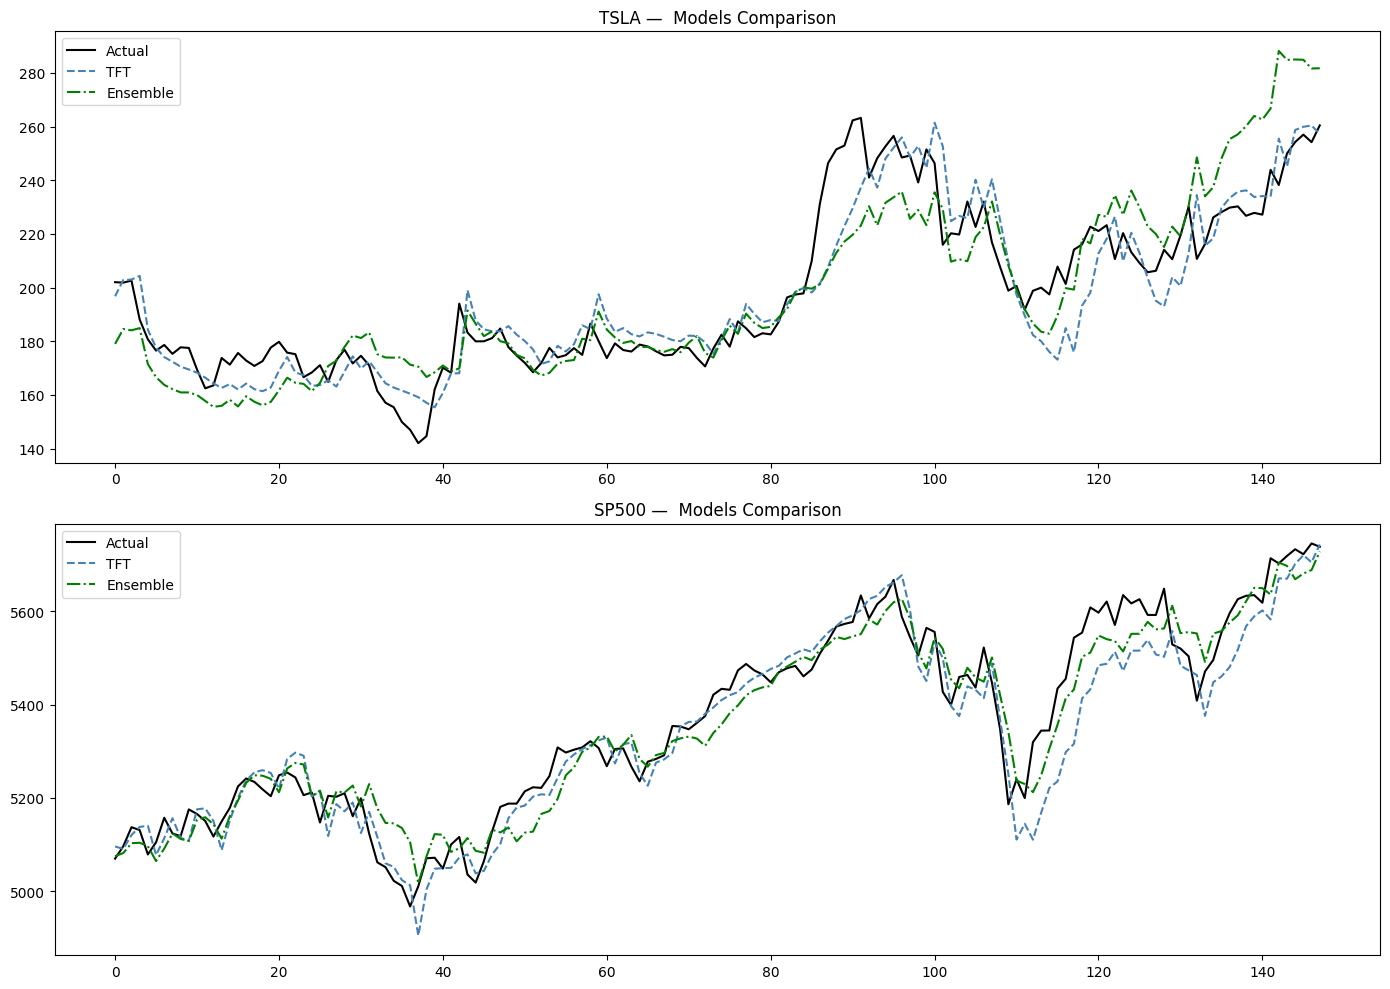

In [46]:
# align everything to TFT
min_tsla  = min(len(y_true_tsla),  len(lstm_preds_tsla),  len(tft_preds_tsla),  len(ensemble_tsla))
min_sp500 = min(len(y_true_sp500), len(lstm_preds_sp500), len(tft_preds_sp500), len(ensemble_sp500))

# normalize lstm to same scale as tft actuals
def align_lstm(lstm_p, tft_actual, n):
    scale = tft_actual[:n].mean() / (lstm_p[:n].mean() + 1e-8)
    return lstm_p[:n] * scale

lstm_tsla_aligned  = align_lstm(lstm_preds_tsla,  y_true_tsla,  min_tsla)
lstm_sp500_aligned = align_lstm(lstm_preds_sp500, y_true_sp500, min_sp500)

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].plot(y_true_tsla[:min_tsla, 0],        label="Actual",    color="black",     linewidth=1.5)

axes[0].plot(tft_preds_tsla[:min_tsla, 0],     label="TFT",       color="steelblue", linestyle="--")
axes[0].plot(ensemble_tsla[:min_tsla, 0],      label="Ensemble",  color="green",     linestyle="-.")
axes[0].set_title("TSLA —  Models Comparison")
axes[0].legend()

axes[1].plot(y_true_sp500[:min_sp500, 0],      label="Actual",    color="black",     linewidth=1.5)

axes[1].plot(tft_preds_sp500[:min_sp500, 0],   label="TFT",       color="steelblue", linestyle="--")
axes[1].plot(ensemble_sp500[:min_sp500, 0],    label="Ensemble",  color="green",     linestyle="-.")
axes[1].set_title("SP500 —  Models Comparison")
axes[1].legend()

plt.tight_layout()
plt.savefig("all_models_comparison.png", dpi=150)
plt.show()

In [57]:
import torch
import torch.nn as nn

class Wrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        output = self.model(x)

        if isinstance(output, tuple):
            output = output[0]

        # select day-1 prediction
        output = output[:, 0]

        # reshape to (batch,1)
        return output.unsqueeze(1)

computing SHAP for SP500...


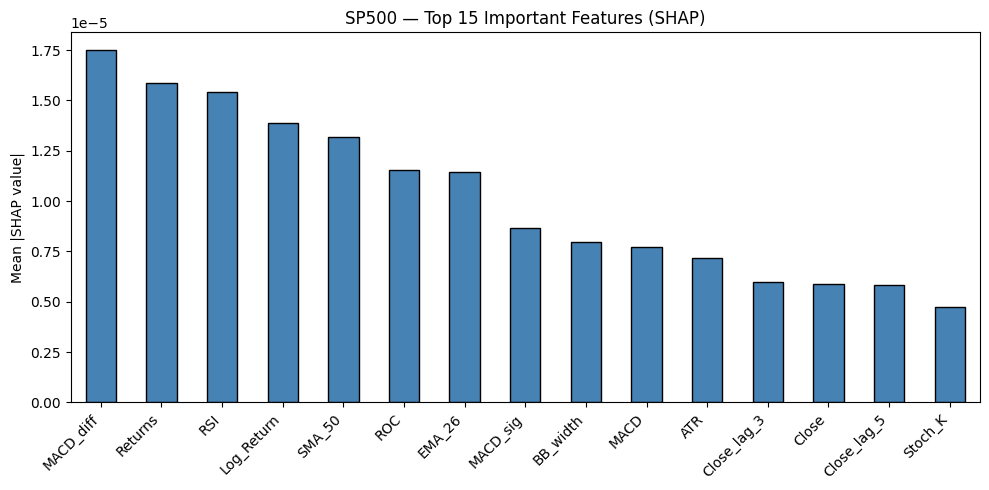


Top 10 features for SP500:
MACD_diff     0.000018
Returns       0.000016
RSI           0.000015
Log_Return    0.000014
SMA_50        0.000013
ROC           0.000012
EMA_26        0.000011
MACD_sig      0.000009
BB_width      0.000008
MACD          0.000008
dtype: float64


In [60]:
import shap

wrapped_sp500 = Wrapper(model_sp500).cpu()
wrapped_sp500.train()

background = X_te_sp500_t[:100].cpu()
test_sample = X_te_sp500_t[100:150].cpu()

print("computing SHAP for SP500...")

explainer = shap.GradientExplainer(wrapped_sp500, background)
shap_vals = explainer.shap_values(test_sample)

# Convert to numpy
shap_array = np.array(shap_vals)

# Average over samples, timesteps, output dim
feature_importance = np.mean(np.abs(shap_array), axis=(0,1,3))

shap_mean_sp = pd.Series(
    feature_importance,
    index=FEATURE_COLS
).sort_values(ascending=False)

plt.figure(figsize=(10,5))
shap_mean_sp[:15].plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("SP500 — Top 15 Important Features (SHAP)")
plt.ylabel("Mean |SHAP value|")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("sp500_shap_bar.png", dpi=150)
plt.show()

print("\nTop 10 features for SP500:")
print(shap_mean_sp[:10])

In [59]:
print(np.array(shap_vals).shape)

(48, 60, 23, 1)


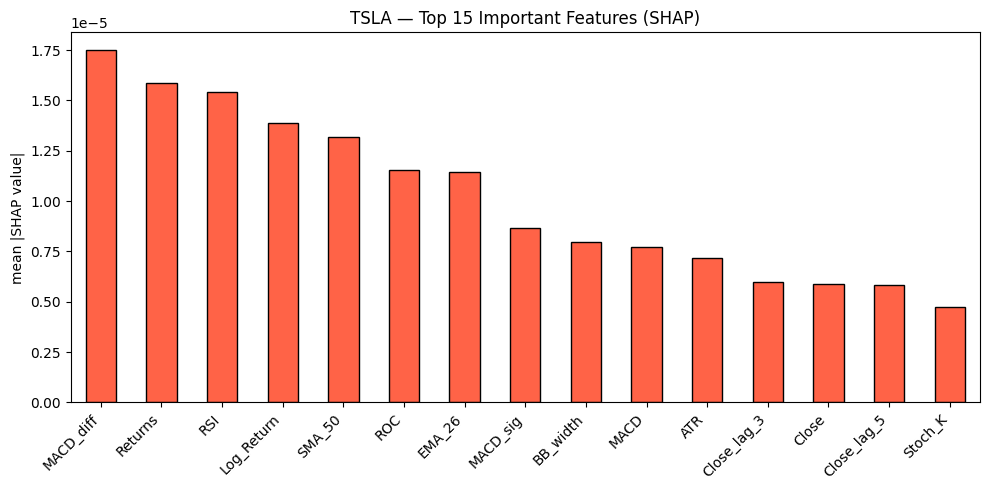


Top 10 features for TSLA:
MACD_diff     0.000018
Returns       0.000016
RSI           0.000015
Log_Return    0.000014
SMA_50        0.000013
ROC           0.000012
EMA_26        0.000011
MACD_sig      0.000009
BB_width      0.000008
MACD          0.000008
dtype: float64


In [61]:
# shap_vals shape: (samples, seq_len, features, pred_len)
# average across samples, timesteps and pred_len to get per feature importance

shap_avg  = np.mean(np.abs(shap_vals), axis=(0, 1, 3))  # (features,) = (23,)
shap_mean = pd.Series(shap_avg, index=FEATURE_COLS).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
shap_mean[:15].plot(kind="bar", color="tomato", edgecolor="black")
plt.title("TSLA — Top 15 Important Features (SHAP)")
plt.ylabel("mean |SHAP value|")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("tsla_shap_bar.png", dpi=150)
plt.show()

print("\nTop 10 features for TSLA:")
print(shap_mean[:10])

computing SHAP for SP500...


/usr/local/lib/python3.12/dist-packages/shap/explainers/_deep/deep_pytorch.py:255: UserWarning: unrecognized nn.Module: LSTM
  warnings.warn(f"unrecognized nn.Module: {module_type}")


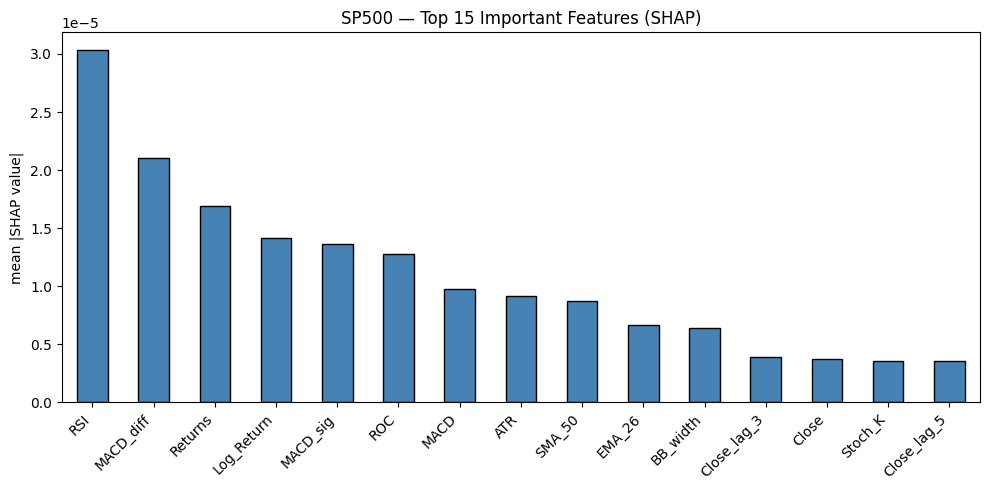


Top 10 features for SP500:
RSI           0.000030
MACD_diff     0.000021
Returns       0.000017
Log_Return    0.000014
MACD_sig      0.000014
ROC           0.000013
MACD          0.000010
ATR           0.000009
SMA_50        0.000009
EMA_26        0.000007
dtype: float64


In [62]:
model_sp500_cpu = model_sp500.cpu().train()
wrapped_sp500   = Wrapper(model_sp500_cpu)

background      = X_te_sp500_t[:50].cpu()
test_sample     = X_te_sp500_t[50:100].cpu()

print("computing SHAP for SP500...")
explainer       = shap.GradientExplainer(wrapped_sp500, background)
shap_vals_sp    = explainer.shap_values(test_sample)

shap_avg_sp  = np.mean(np.abs(shap_vals_sp), axis=(0, 1, 3))
shap_mean_sp = pd.Series(shap_avg_sp, index=FEATURE_COLS).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
shap_mean_sp[:15].plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("SP500 — Top 15 Important Features (SHAP)")
plt.ylabel("mean |SHAP value|")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("sp500_shap_bar.png", dpi=150)
plt.show()

print("\nTop 10 features for SP500:")
print(shap_mean_sp[:10])

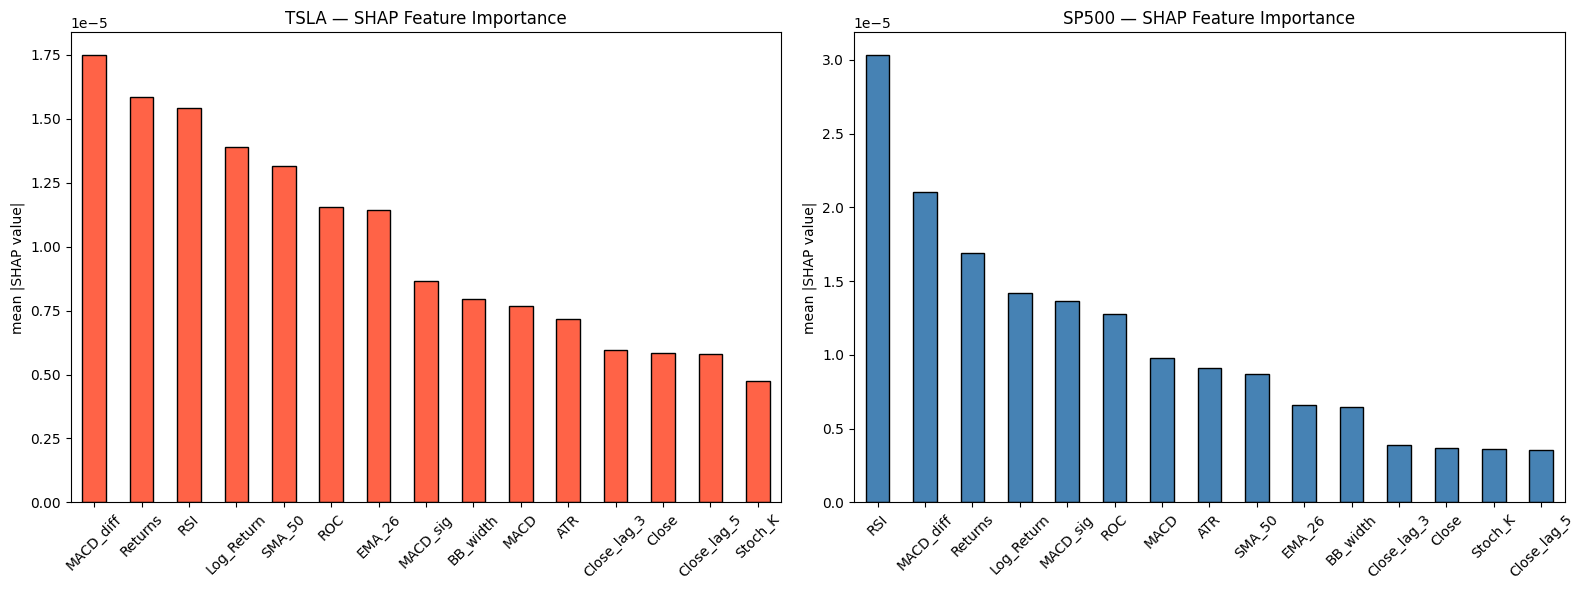

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

shap_mean[:15].plot(kind="bar",    color="tomato",    edgecolor="black", ax=axes[0])
axes[0].set_title("TSLA — SHAP Feature Importance")
axes[0].set_ylabel("mean |SHAP value|")
axes[0].tick_params(axis="x", rotation=45)

shap_mean_sp[:15].plot(kind="bar", color="steelblue", edgecolor="black", ax=axes[1])
axes[1].set_title("SP500 — SHAP Feature Importance")
axes[1].set_ylabel("mean |SHAP value|")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("shap_comparison.png", dpi=150)
plt.show()

In [64]:
def get_tft_preds_with_intervals(model, test_ds, stock_name):
    test_dl = test_ds.to_dataloader(train=False, batch_size=64, num_workers=0, shuffle=False)

    # mode="raw" returns a dictionary containing predictions for ALL quantiles
    output = model.predict(
        test_dl,
        mode="raw",
        return_x=True,
        trainer_kwargs={"logger": False, "accelerator": "gpu" if torch.cuda.is_available() else "cpu", "devices": 1}
    )

    # TFT usually predicts [0.02, 0.1, 0.25, 0.5, 0.75, 0.9, 0.98]
    # We want index 1 (10th percentile), 3 (50th/Median), and 5 (90th percentile)
    preds = output.output.prediction.cpu().numpy()

    low_bound = preds[:, :, 1]  # 10th percentile
    median    = preds[:, :, 3]  # 50th percentile (Point prediction)
    high_bound = preds[:, :, 5]  # 90th percentile

    # Get actuals
    actuals = torch.cat([y[0] for x, y in iter(test_dl)]).numpy()

    print(f"{stock_name} — Quantile shapes: {median.shape}")
    return low_bound, median, high_bound, actuals

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


TSLA — Quantile shapes: (208, 5)


/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


SP500 — Quantile shapes: (208, 5)


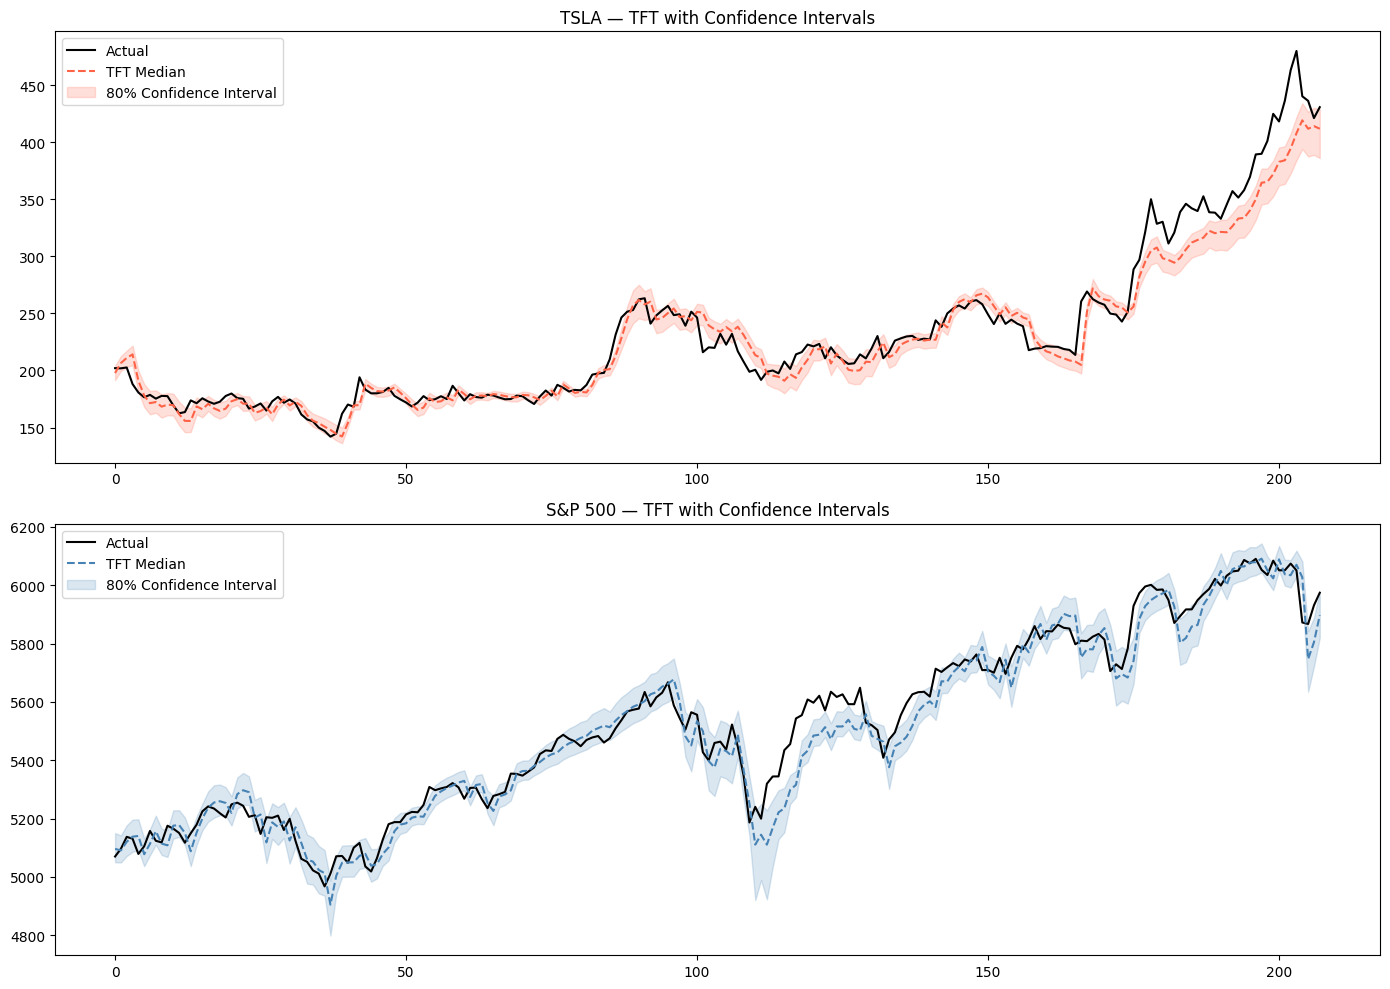

In [65]:
# Get predictions with intervals
low_tsla, med_tsla, high_tsla, act_tsla = get_tft_preds_with_intervals(tft_tsla, tft_test_tsla, "TSLA")
low_sp, med_sp, high_sp, act_sp = get_tft_preds_with_intervals(tft_sp500, tft_test_sp500, "SP500")

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# TSLA Plot
axes[0].plot(act_tsla[:, 0], label="Actual", color="black", linewidth=1.5)
axes[0].plot(med_tsla[:, 0], label="TFT Median", color="tomato", linestyle="--")
axes[0].fill_between(
    range(len(med_tsla)),
    low_tsla[:, 0], high_tsla[:, 0],
    color="tomato", alpha=0.2, label="80% Confidence Interval"
)
axes[0].set_title("TSLA — TFT with Confidence Intervals")
axes[0].legend()

# SP500 Plot
axes[1].plot(act_sp[:, 0], label="Actual", color="black", linewidth=1.5)
axes[1].plot(med_sp[:, 0], label="TFT Median", color="steelblue", linestyle="--")
axes[1].fill_between(
    range(len(med_sp)),
    low_sp[:, 0], high_sp[:, 0],
    color="steelblue", alpha=0.2, label="80% Confidence Interval"
)
axes[1].set_title("S&P 500 — TFT with Confidence Intervals")
axes[1].legend()

plt.tight_layout()
plt.show()